# Function Encoders: Learning Basis Representations for Operator Learning

**Learning Objectives:**
- Understand function representations in Hilbert space using basis functions
- Learn to compute coefficients using least squares (with derivation) and Monte Carlo integration
- Compare classical fixed bases (Fourier, polynomial, RBF) with learned neural network bases
- Implement function encoders using neural networks to learn adaptive basis functions
- Achieve orthonormality through Gram matrix regularization
- Understand basis trimming to remove redundant functions
- Apply linearity of coefficients in Hilbert space for function composition
- Train a nested basis with a Matryoshka loss and compare it with POD
- State the finite-sample and noise guarantees of least-squares inference and check them numerically

**Exercise:** [![Open in Colab](https://img.shields.io/badge/Open%20in-Colab-F9AB00?style=flat-square&logo=googlecolab)](https://colab.research.google.com/github/kks32-courses/sciml/blob/main/docs/03-function-encoder/03-function-encoder-exercise.ipynb)
**Solution:** [![Open in Colab](https://img.shields.io/badge/Open%20in-Colab-F9AB00?style=flat-square&logo=googlecolab)](https://colab.research.google.com/github/kks32-courses/sciml/blob/main/docs/03-function-encoder/03-function-encoder.ipynb)

---

## Introduction

**Function encoders** represent functions in a Hilbert space as linear combinations of basis functions:

$$f(x) = \sum_{j=1}^d \alpha_j \phi_j(x)$$

**Key innovation:** Instead of using fixed basis functions (Fourier, polynomials), we **learn** the basis $\{\phi_j\}$ using neural networks to adapt to the function family.

**This notebook:**
1. Background on computing coefficients from basis functions
2. Classical fixed bases and their limitations
3. Learning basis functions with neural networks (function encoders)
4. Achieving orthonormality and basis trimming
5. Nested bases with a Matryoshka loss
6. Linearity of coefficients in Hilbert space
7. Guarantees at inference time (finite-sample bound, noise amplification)

In [20]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from tqdm import tqdm

np.random.seed(42)
torch.manual_seed(42)

device = torch.device("cpu")
print(f"Device: {device}")

Device: cpu


---

## Part 1: Background - Computing Coefficients

Given basis functions $\{\phi_j(x)\}$ and a target function $f(x)$, we need to compute coefficients $\{\alpha_j\}$.

### Method 1: Least Squares (Derivation)

Given samples $\{(x_i, f(x_i))\}_{i=1}^m$, minimize reconstruction error:

$$\min_{\alpha} \sum_{i=1}^m \left( f(x_i) - \sum_{j=1}^d \alpha_j \phi_j(x_i) \right)^2$$

Define basis matrix $\Phi \in \mathbb{R}^{m \times d}$ where $\Phi_{ij} = \phi_j(x_i)$:

$$\min_{\alpha} \|\Phi \alpha - f\|_2^2$$

**Derivation:**

Taking gradient with respect to $\alpha$:

$$\nabla_{\alpha} \|\Phi \alpha - f\|_2^2 = \nabla_{\alpha} (\Phi \alpha - f)^T (\Phi \alpha - f)$$

$$= \nabla_{\alpha} (\alpha^T \Phi^T \Phi \alpha - 2f^T \Phi \alpha + f^T f)$$

$$= 2\Phi^T \Phi \alpha - 2\Phi^T f$$

Setting to zero:

$$\Phi^T \Phi \alpha = \Phi^T f$$

$$\boxed{\alpha = (\Phi^T \Phi)^{-1} \Phi^T f}$$

This is the **normal equation**.

### Method 2: Monte Carlo Integration

For orthonormal basis where $\langle \phi_i, \phi_j \rangle = \delta_{ij}$:

$$\alpha_i = \langle f, \phi_i \rangle = \int_{\mathcal{X}} f(x) \phi_i(x) \, dx$$

**Approximate with samples:**

$$\alpha_i \approx \frac{1}{N} \sum_{k=1}^N f(x_k) \phi_i(x_k) \cdot V$$

where $V = |\mathcal{X}|$ is the domain volume.

**Note:** MC integration assumes orthonormal basis. If basis is not orthonormal, LS is more accurate.

---

## Part 2: Classical Basis Functions

We compare three classical fixed bases: Fourier, Polynomial, and RBF.

**Target:** Gaussian bump family

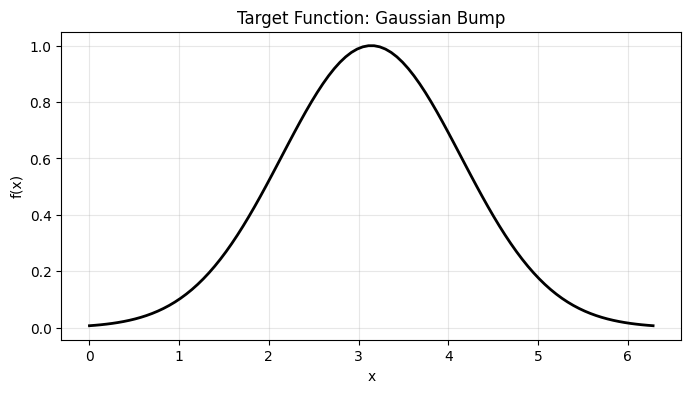

Target: Gaussian centered at π


In [21]:
# Target function family
def target_function(x, center=np.pi, width=1.0, amplitude=1.0):
    return amplitude * np.exp(-((x - center) ** 2) / (2 * width ** 2))

x = np.linspace(0, 2*np.pi, 100)
y_true = target_function(x)

plt.figure(figsize=(8, 4))
plt.plot(x, y_true, 'k-', linewidth=2)
plt.title('Target Function: Gaussian Bump')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.grid(True, alpha=0.3)
plt.show()

print(f"Target: Gaussian centered at π")

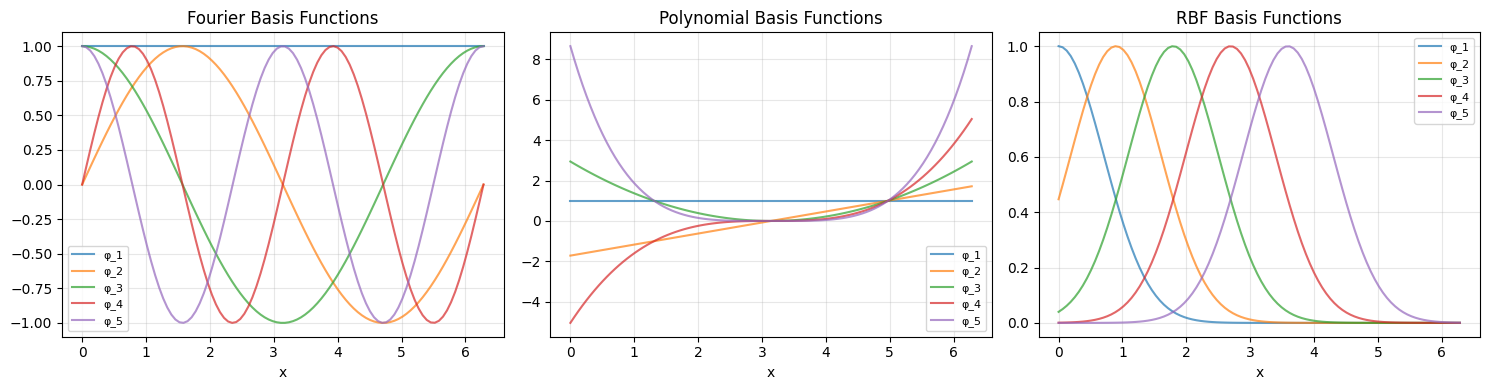

In [22]:
# Classical basis functions
def fourier_basis(x, n_basis):
    basis = [np.ones_like(x)]
    for k in range(1, n_basis//2 + 1):
        basis.append(np.sin(k * x))
        if len(basis) < n_basis:
            basis.append(np.cos(k * x))
    return np.column_stack(basis[:n_basis])

def polynomial_basis(x, n_basis):
    x_norm = (x - x.mean()) / (x.std() + 1e-8)
    return np.column_stack([x_norm**i for i in range(n_basis)])

def rbf_basis(x, n_basis, gamma=1.0):
    centers = np.linspace(x.min(), x.max(), n_basis)
    return np.exp(-gamma * (x[:, None] - centers) ** 2)

n_basis = 8

# Visualize
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

basis_funcs = [
    (fourier_basis(x, n_basis), 'Fourier'),
    (polynomial_basis(x, n_basis), 'Polynomial'),
    (rbf_basis(x, n_basis), 'RBF')
]

for ax, (basis, name) in zip(axes, basis_funcs):
    for i in range(min(5, n_basis)):
        ax.plot(x, basis[:, i], alpha=0.7, label=f'φ_{i+1}')
    ax.set_title(f'{name} Basis Functions')
    ax.set_xlabel('x')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Fourier      MSE: 0.000000
Polynomial   MSE: 0.000265
RBF          MSE: 0.000002


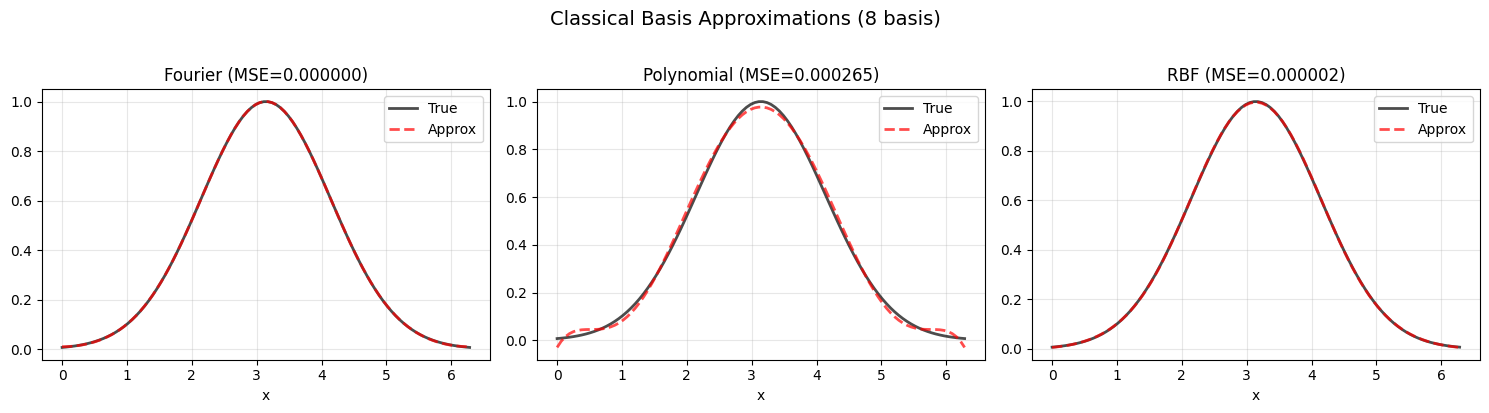

In [23]:
# Compare approximations using least squares
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (Phi, name) in zip(axes, basis_funcs):
    alpha = np.linalg.lstsq(Phi, y_true, rcond=None)[0]
    y_pred = Phi @ alpha
    mse = np.mean((y_true - y_pred) ** 2)
    
    ax.plot(x, y_true, 'k-', linewidth=2, label='True', alpha=0.7)
    ax.plot(x, y_pred, 'r--', linewidth=2, label='Approx', alpha=0.7)
    ax.set_title(f'{name} (MSE={mse:.6f})')
    ax.set_xlabel('x')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    print(f"{name:12s} MSE: {mse:.6f}")

plt.suptitle(f'Classical Basis Approximations ({n_basis} basis)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### Demonstrating Least Squares vs Monte Carlo

We use RBF basis to show both methods.

In [24]:
# RBF basis for detailed comparison
n_rbf = 10
x_fine = np.linspace(0, 2*np.pi, 200)
Phi_rbf = rbf_basis(x_fine, n_rbf, gamma=2.0)
f_target = target_function(x_fine, center=np.pi, width=0.8)

# Manual least squares calculation (showing the derivation)
print("Manual Least Squares Calculation:")
print("="*60)
PhiT = Phi_rbf.T
PhiT_Phi = PhiT @ Phi_rbf
print(f"Φ^T Φ shape: {PhiT_Phi.shape}")
PhiT_f = PhiT @ f_target
print(f"Φ^T f shape: {PhiT_f.shape}")
alpha_ls_manual = np.linalg.solve(PhiT_Phi, PhiT_f)
print(f"α = (Φ^T Φ)^-1 Φ^T f computed")
f_recon_ls = Phi_rbf @ alpha_ls_manual
mse_ls = np.mean((f_target - f_recon_ls) ** 2)
print(f"LS MSE: {mse_ls:.8f}\n")

# Monte Carlo integration
print("Monte Carlo Integration:")
print("="*60)
dx = x_fine[1] - x_fine[0]
V = x_fine[-1] - x_fine[0]
# MC: α_i = <f, φ_i> ≈ (1/N) Σ f(x_k)φ_i(x_k) * V
alpha_mc = (V / len(x_fine)) * np.sum(f_target[:, None] * Phi_rbf, axis=0)
f_recon_mc = Phi_rbf @ alpha_mc
mse_mc = np.mean((f_target - f_recon_mc) ** 2)
print(f"MC MSE: {mse_mc:.8f}\n")

# Check Gram matrix
G_rbf = Phi_rbf.T @ Phi_rbf * dx
ortho_error = np.linalg.norm(G_rbf - np.eye(n_rbf), 'fro')
print(f"Gram matrix orthonormality error: {ortho_error:.4f}")
print(f"Conclusion: RBF basis is NOT orthonormal, so LS is more accurate")

Manual Least Squares Calculation:
Φ^T Φ shape: (10, 10)
Φ^T f shape: (10,)
α = (Φ^T Φ)^-1 Φ^T f computed
LS MSE: 0.00000193

Monte Carlo Integration:
MC MSE: 0.21518306

Gram matrix orthonormality error: 2.4396
Conclusion: RBF basis is NOT orthonormal, so LS is more accurate


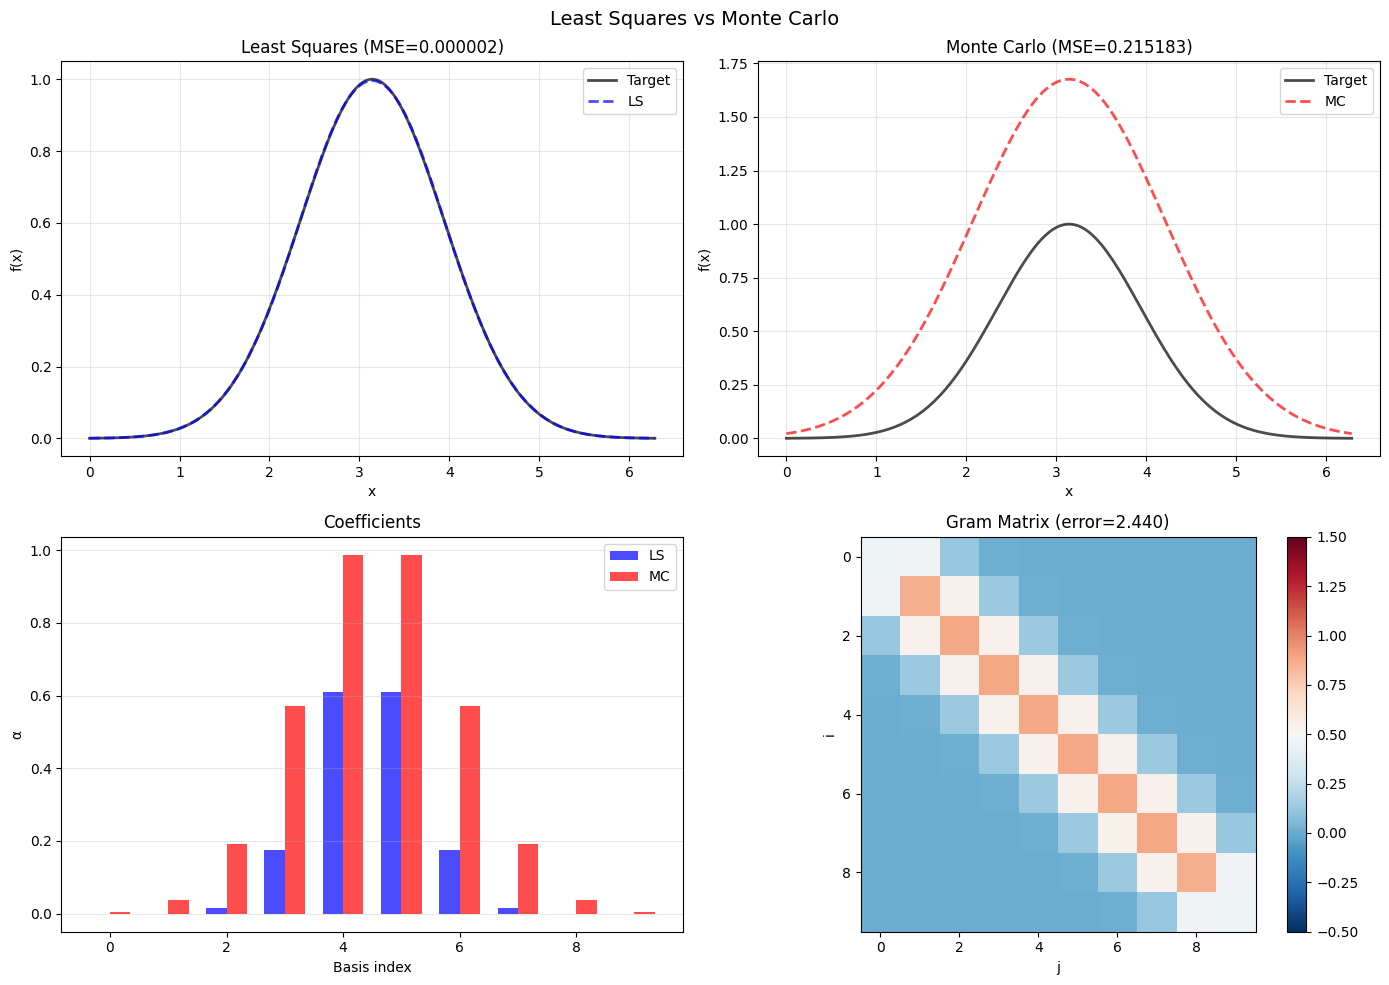

In [25]:
# Visualize LS vs MC
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

ax = axes[0, 0]
ax.plot(x_fine, f_target, 'k-', linewidth=2, label='Target', alpha=0.7)
ax.plot(x_fine, f_recon_ls, 'b--', linewidth=2, label='LS', alpha=0.7)
ax.set_title(f'Least Squares (MSE={mse_ls:.6f})')
ax.set_xlabel('x')
ax.set_ylabel('f(x)')
ax.legend()
ax.grid(True, alpha=0.3)

ax = axes[0, 1]
ax.plot(x_fine, f_target, 'k-', linewidth=2, label='Target', alpha=0.7)
ax.plot(x_fine, f_recon_mc, 'r--', linewidth=2, label='MC', alpha=0.7)
ax.set_title(f'Monte Carlo (MSE={mse_mc:.6f})')
ax.set_xlabel('x')
ax.set_ylabel('f(x)')
ax.legend()
ax.grid(True, alpha=0.3)

ax = axes[1, 0]
idx = np.arange(n_rbf)
width = 0.35
ax.bar(idx - width/2, alpha_ls_manual, width, label='LS', alpha=0.7, color='blue')
ax.bar(idx + width/2, alpha_mc, width, label='MC', alpha=0.7, color='red')
ax.set_title('Coefficients')
ax.set_xlabel('Basis index')
ax.set_ylabel('α')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

ax = axes[1, 1]
im = ax.imshow(G_rbf, cmap='RdBu_r', vmin=-0.5, vmax=1.5)
ax.set_title(f'Gram Matrix (error={ortho_error:.3f})')
ax.set_xlabel('j')
ax.set_ylabel('i')
plt.colorbar(im, ax=ax)

plt.suptitle('Least Squares vs Monte Carlo', fontsize=14)
plt.tight_layout()
plt.show()

**Observation:** RBF basis is not orthonormal (Gram matrix $\neq I$), so least squares gives better reconstruction than Monte Carlo integration.

---

## Part 3: Learning Basis Functions (Function Encoders)

**Key idea:** Use neural networks to **learn** basis functions $\{\phi_j(x; \theta_j)\}$ adapted to the function family.

### Architecture 1: Single MLP

One network outputs all basis functions: $\phi(x; \theta): \mathbb{R} \to \mathbb{R}^d$

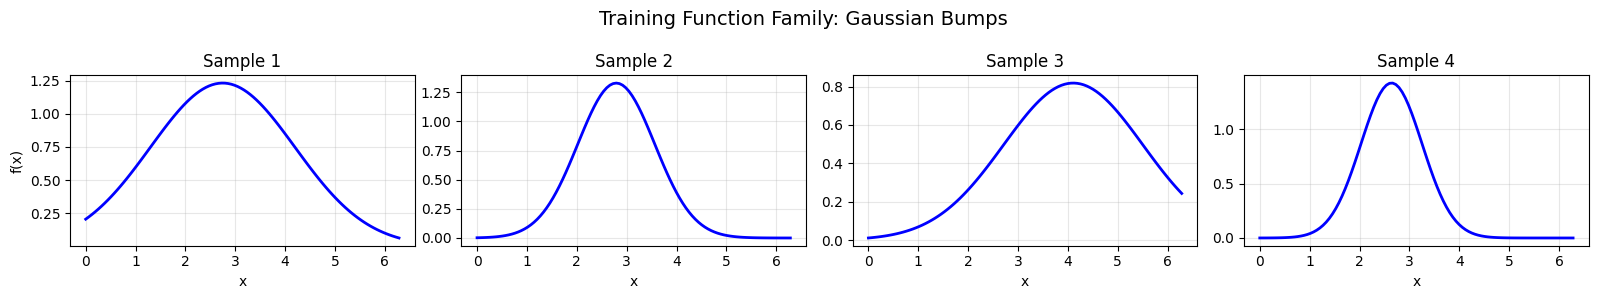

Dataset: 500 train, 100 test functions


In [26]:
# Create dataset: family of Gaussian bumps
def create_function_dataset(n_samples=500, n_points=100):
    x_data = np.linspace(0, 2*np.pi, n_points)
    functions = []
    
    for _ in range(n_samples):
        center = np.random.uniform(np.pi/2, 3*np.pi/2)
        width = np.random.uniform(0.5, 1.5)
        amplitude = np.random.uniform(0.5, 1.5)
        y = target_function(x_data, center, width, amplitude)
        functions.append(y)
    
    return x_data, np.array(functions)

x_train, f_train = create_function_dataset(n_samples=500)
x_test, f_test = create_function_dataset(n_samples=100)

x_torch = torch.FloatTensor(x_train)
f_torch = torch.FloatTensor(f_train)
x_test_torch = torch.FloatTensor(x_test)
f_test_torch = torch.FloatTensor(f_test)

# Visualize dataset
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for i, ax in enumerate(axes):
    ax.plot(x_train, f_train[i*20], 'b-', linewidth=2)
    ax.set_title(f'Sample {i+1}')
    ax.set_xlabel('x')
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel('f(x)')
plt.suptitle('Training Function Family: Gaussian Bumps', fontsize=14)
plt.tight_layout()
plt.show()

print(f"Dataset: {len(f_train)} train, {len(f_test)} test functions")

In [ ]:
class SingleMLPBasis(nn.Module):
    def __init__(self, n_basis, hidden=64):
        super().__init__()
        self.n_basis = n_basis
        # TODO: Define network architecture
        # Hint: Input dim = 1, output dim = n_basis
        # Use hidden layers with Tanh activation
        
        
        
        
        
        
        
        self.net = None  # Your code here
    
    def forward(self, x):
        # TODO: Implement forward pass
        # Hint: Handle 1D input by adding dimension if needed
        
        
        
        
        
        
        pass  # Your code here

def train_function_encoder(model, x, f, n_epochs=200, lr=1e-3):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    losses = []
    
    for epoch in tqdm(range(n_epochs), desc="Training"):
        model.train()
        # TODO: Get basis functions Phi from model
        
        
        
        Phi = None  # Your code here
        
        # TODO: Solve for coefficients using least squares
        # Hint: α = (Φ^T Φ)^-1 Φ^T f
        # Use torch.linalg.solve for numerical stability
        
        
        
        
        
        
        PhiT_Phi = None  # Your code here
        PhiT_f = None  # Your code here
        alpha = None  # Your code here
        
        # TODO: Reconstruct functions and compute MSE loss
        
        
        
        
        
        f_pred = None  # Your code here
        loss = None  # Your code here
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    
    return losses

model_single = SingleMLPBasis(n_basis=8)
losses_single = train_function_encoder(model_single, x_torch, f_torch)

plt.figure(figsize=(8, 4))
plt.plot(losses_single)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Single MLP Training')
plt.yscale('log')
plt.grid(True, alpha=0.3)
plt.show()

print(f"Final loss: {losses_single[-1]:.6f}")

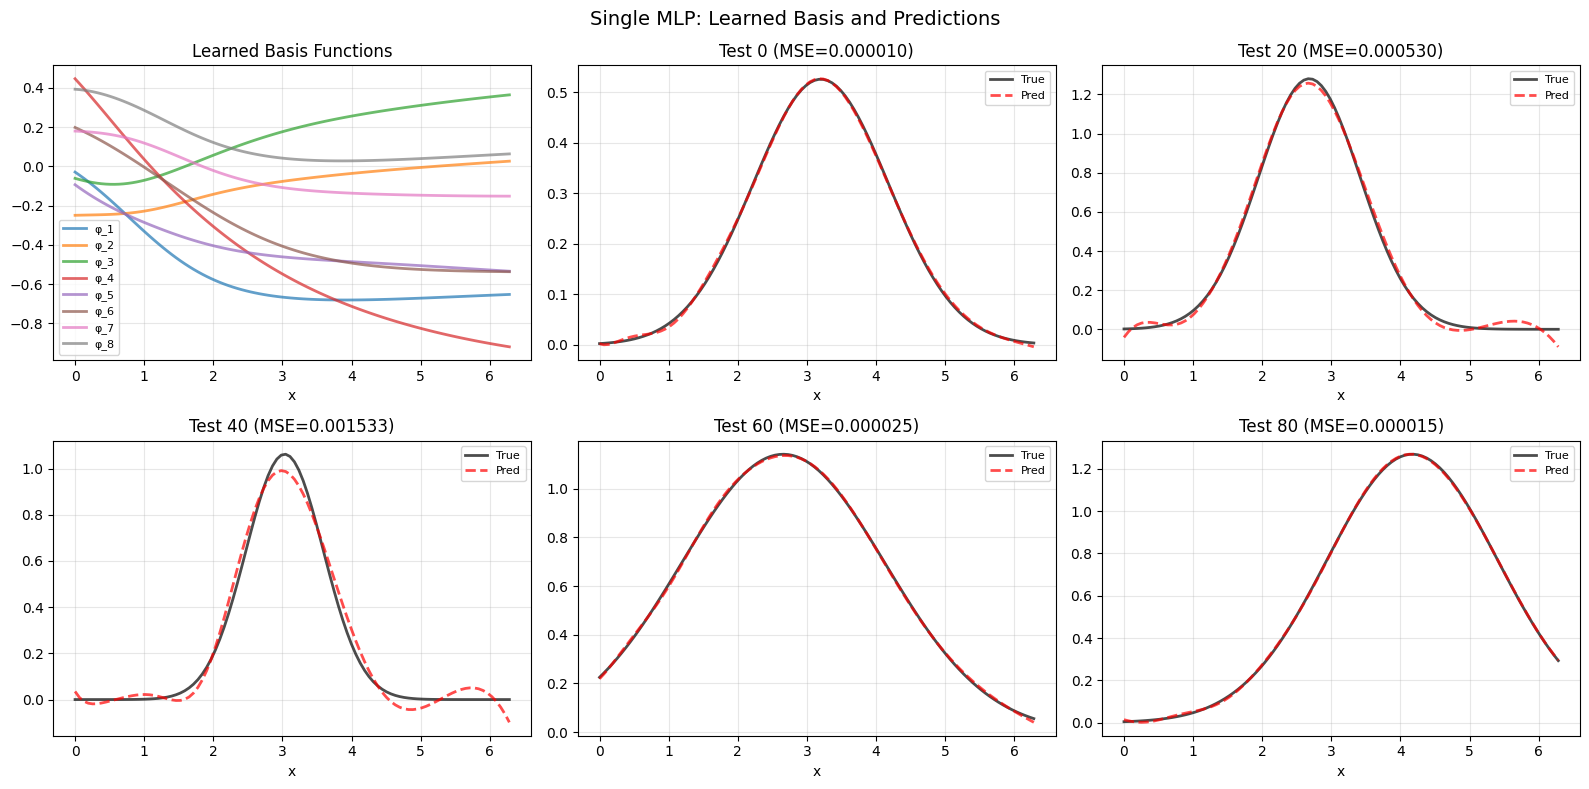

In [28]:
# Visualize learned basis and predictions
model_single.eval()
with torch.no_grad():
    Phi_learned = model_single(x_torch).numpy()

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

# Basis functions
ax = axes[0, 0]
for i in range(model_single.n_basis):
    ax.plot(x_train, Phi_learned[:, i], alpha=0.7, linewidth=2, label=f'φ_{i+1}')
ax.set_title('Learned Basis Functions')
ax.set_xlabel('x')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# Test predictions
test_indices = [0, 20, 40, 60, 80]
for col, idx in enumerate(test_indices[:5]):
    if col < 2:
        ax = axes[0, col+1]
    else:
        ax = axes[1, col-2]
    
    with torch.no_grad():
        Phi_test = model_single(x_test_torch)
        PhiT_Phi = Phi_test.T @ Phi_test
        PhiT_f = Phi_test.T @ f_test_torch[idx]
        alpha = torch.linalg.solve(PhiT_Phi, PhiT_f)
        f_recon = (Phi_test @ alpha).numpy()
    
    mse = np.mean((f_test[idx] - f_recon) ** 2)
    ax.plot(x_test, f_test[idx], 'k-', linewidth=2, label='True', alpha=0.7)
    ax.plot(x_test, f_recon, 'r--', linewidth=2, label='Pred', alpha=0.7)
    ax.set_title(f'Test {idx} (MSE={mse:.6f})')
    ax.set_xlabel('x')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle('Single MLP: Learned Basis and Predictions', fontsize=14)
plt.tight_layout()
plt.show()

### Architecture 2: Separate MLPs

Each basis function is a separate network: $\phi_j(x; \theta_j): \mathbb{R} \to \mathbb{R}$

In [ ]:
class SeparateMLPBasis(nn.Module):
    def __init__(self, n_basis, hidden=32):
        super().__init__()
        self.n_basis = n_basis
        # TODO: Create n_basis separate neural networks
        # Hint: Each network maps R -> R (input dim=1, output dim=1)
        # Use nn.ModuleList to store multiple networks
        
        
        
        
        
        
        
        
        
        
        self.networks = None  # Your code here
    
    def forward(self, x):
        # TODO: Implement forward pass
        # Hint: Apply each network and concatenate outputs
        # Handle 1D input by adding dimension if needed
        
        
        
        
        
        
        
        pass  # Your code here

model_separate = SeparateMLPBasis(n_basis=8)
losses_separate = train_function_encoder(model_separate, x_torch, f_torch, n_epochs=200)

plt.figure(figsize=(8, 4))
plt.plot(losses_separate)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Separate MLPs Training')
plt.yscale('log')
plt.grid(True, alpha=0.3)
plt.show()

print(f"Final loss: {losses_separate[-1]:.6f}")

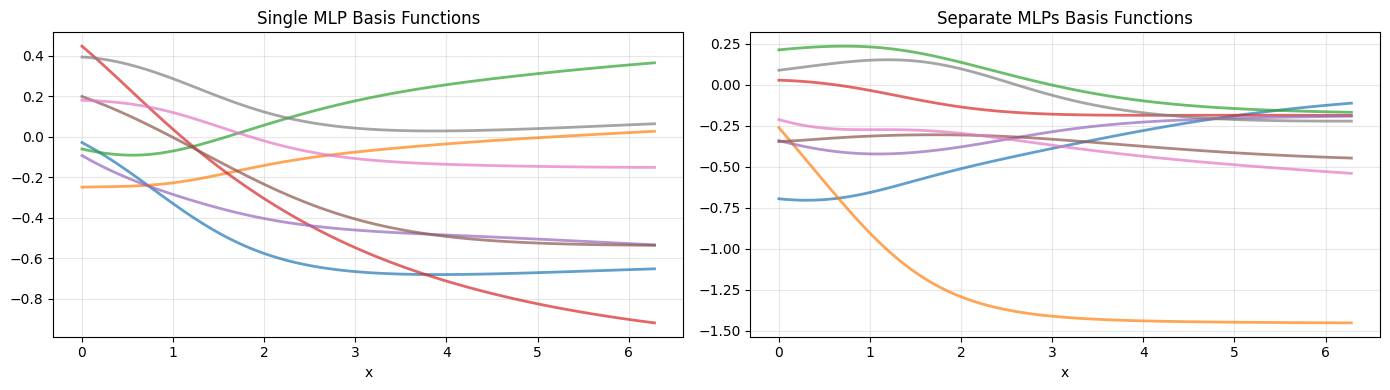

Single MLP   - Params: 4,808
Separate MLP - Params: 9,224


In [30]:
# Compare architectures
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, model, name in [(axes[0], model_single, 'Single MLP'),
                         (axes[1], model_separate, 'Separate MLPs')]:
    model.eval()
    with torch.no_grad():
        Phi = model(x_torch).numpy()
    
    for i in range(model.n_basis):
        ax.plot(x_train, Phi[:, i], alpha=0.7, linewidth=2)
    ax.set_title(f'{name} Basis Functions')
    ax.set_xlabel('x')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Single MLP   - Params: {sum(p.numel() for p in model_single.parameters()):,}")
print(f"Separate MLP - Params: {sum(p.numel() for p in model_separate.parameters()):,}")

---

## Part 4: Achieving Orthonormality via Gram Matrix

The **Gram matrix** measures orthonormality:

$$G_{ij} = \langle \phi_i, \phi_j \rangle = \int \phi_i(x) \phi_j(x) dx \approx \sum_k \phi_i(x_k) \phi_j(x_k) \Delta x$$

**Ideal:** $G = I$ (orthonormal basis)

Analyzing Separate MLPs (before orthonormalization):


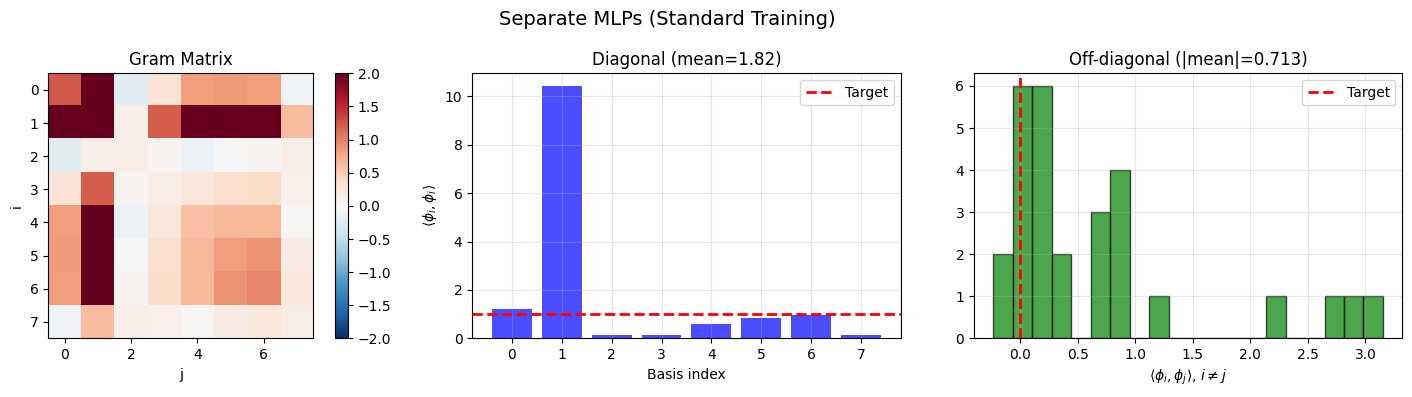

Orthonormality deviation: 12.8401
Diagonal: 1.816 ± 3.276
Off-diagonal: 0.7126


In [31]:
def compute_gram_matrix(model, x):
    model.eval()
    with torch.no_grad():
        Phi = model(x).numpy()
    dx = (x[-1] - x[0]) / (len(x) - 1)
    G = Phi.T @ Phi * dx.item()
    return G

def plot_gram_analysis(model, x, title):
    G = compute_gram_matrix(model, x)
    n = G.shape[0]
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    
    ax = axes[0]
    im = ax.imshow(G, cmap='RdBu_r', vmin=-2, vmax=2)
    ax.set_title('Gram Matrix')
    ax.set_xlabel('j')
    ax.set_ylabel('i')
    plt.colorbar(im, ax=ax)
    
    ax = axes[1]
    diag = np.diag(G)
    ax.bar(range(n), diag, alpha=0.7, color='blue')
    ax.axhline(1.0, color='red', linestyle='--', linewidth=2, label='Target')
    ax.set_title(f'Diagonal (mean={diag.mean():.2f})')
    ax.set_xlabel('Basis index')
    ax.set_ylabel(r'$\langle \phi_i, \phi_i \rangle$')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    ax = axes[2]
    off_diag = G[np.triu_indices(n, k=1)]
    if len(off_diag) > 0:
        ax.hist(off_diag, bins=20, alpha=0.7, edgecolor='black', color='green')
        ax.axvline(0, color='red', linestyle='--', linewidth=2, label='Target')
        ax.set_title(f'Off-diagonal (|mean|={np.abs(off_diag).mean():.3f})')
        ax.set_xlabel(r'$\langle \phi_i, \phi_j \rangle$, $i \neq j$')
        ax.legend()
    ax.grid(True, alpha=0.3)
    
    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()
    
    ortho_score = np.linalg.norm(G - np.eye(n), 'fro')
    print(f"Orthonormality deviation: {ortho_score:.4f}")
    print(f"Diagonal: {diag.mean():.3f} ± {diag.std():.3f}")
    if len(off_diag) > 0:
        print(f"Off-diagonal: {np.abs(off_diag).mean():.4f}")

print("Analyzing Separate MLPs (before orthonormalization):")
plot_gram_analysis(model_separate, x_torch, "Separate MLPs (Standard Training)")

### Two-Stage Training for Orthonormality

**Stage 1:** Train with Gram loss  
$$\mathcal{L} = \mathcal{L}_{\text{recon}} + \lambda \|G - I\|_F^2$$

**Stage 2:** Fine-tune with reconstruction only

Stage 1: Training with Gram loss


100%|██████████| 150/150 [00:00<00:00, 214.10it/s]


Stage 2: Fine-tuning without Gram loss


100%|██████████| 50/50 [00:00<00:00, 314.86it/s]


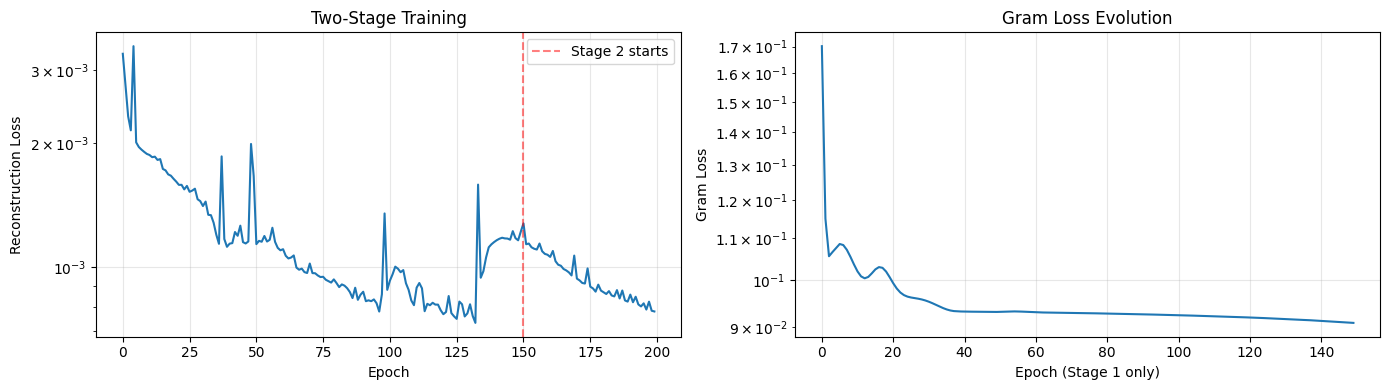

Final reconstruction loss: 0.000782
Final Gram loss: 0.090812


In [32]:
def gram_loss(model, x):
    Phi = model(x)
    dx = (x[-1] - x[0]) / (len(x) - 1)
    G = Phi.T @ Phi * dx
    I = torch.eye(model.n_basis)
    return torch.mean((G - I) ** 2)

def train_two_stage(model, x, f, lambda_gram=1.0, n_epochs_s1=150, n_epochs_s2=50, lr=1e-3):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    losses_recon = []
    losses_gram = []
    
    print("Stage 1: Training with Gram loss")
    for epoch in tqdm(range(n_epochs_s1)):
        model.train()
        Phi = model(x)
        PhiT_Phi = Phi.T @ Phi
        PhiT_f = Phi.T @ f.T
        alpha = torch.linalg.solve(PhiT_Phi, PhiT_f)
        f_pred = Phi @ alpha
        loss_recon = torch.mean((f.T - f_pred) ** 2)
        loss_g = gram_loss(model, x)
        loss = loss_recon + lambda_gram * loss_g
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses_recon.append(loss_recon.item())
        losses_gram.append(loss_g.item())
    
    print("Stage 2: Fine-tuning without Gram loss")
    for epoch in tqdm(range(n_epochs_s2)):
        model.train()
        Phi = model(x)
        PhiT_Phi = Phi.T @ Phi
        PhiT_f = Phi.T @ f.T
        alpha = torch.linalg.solve(PhiT_Phi, PhiT_f)
        f_pred = Phi @ alpha
        loss = torch.mean((f.T - f_pred) ** 2)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses_recon.append(loss.item())
    
    return losses_recon, losses_gram

model_ortho = SeparateMLPBasis(n_basis=8)
losses_recon, losses_gram = train_two_stage(model_ortho, x_torch, f_torch, lambda_gram=0.5)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ax1.plot(losses_recon)
ax1.axvline(150, color='red', linestyle='--', alpha=0.5, label='Stage 2 starts')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Reconstruction Loss')
ax1.set_title('Two-Stage Training')
ax1.set_yscale('log')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(losses_gram)
ax2.set_xlabel('Epoch (Stage 1 only)')
ax2.set_ylabel('Gram Loss')
ax2.set_title('Gram Loss Evolution')
ax2.set_yscale('log')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Final reconstruction loss: {losses_recon[-1]:.6f}")
print(f"Final Gram loss: {losses_gram[-1]:.6f}")


WITHOUT Orthonormalization:


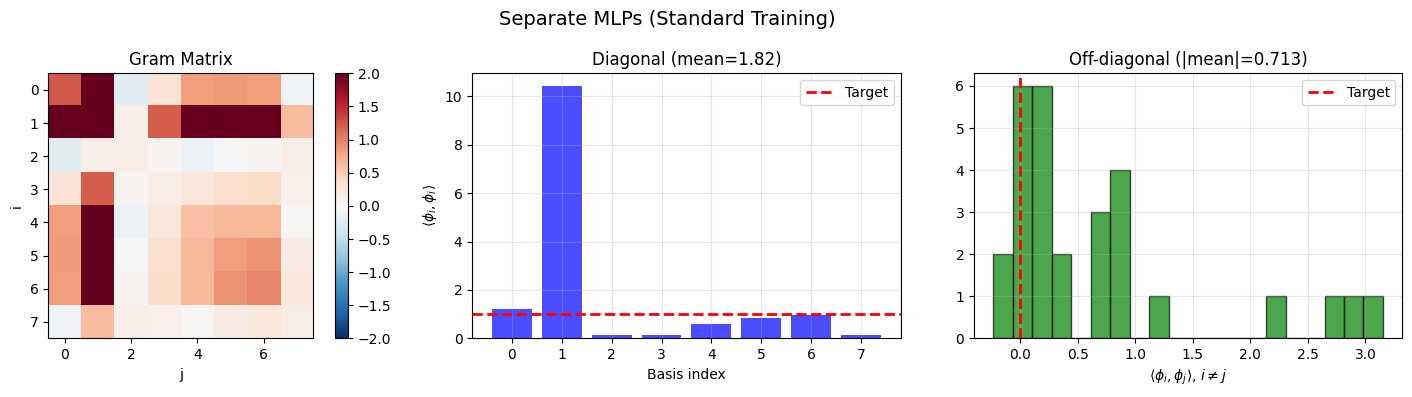

Orthonormality deviation: 12.8401
Diagonal: 1.816 ± 3.276
Off-diagonal: 0.7126

WITH Orthonormalization (Two-Stage):


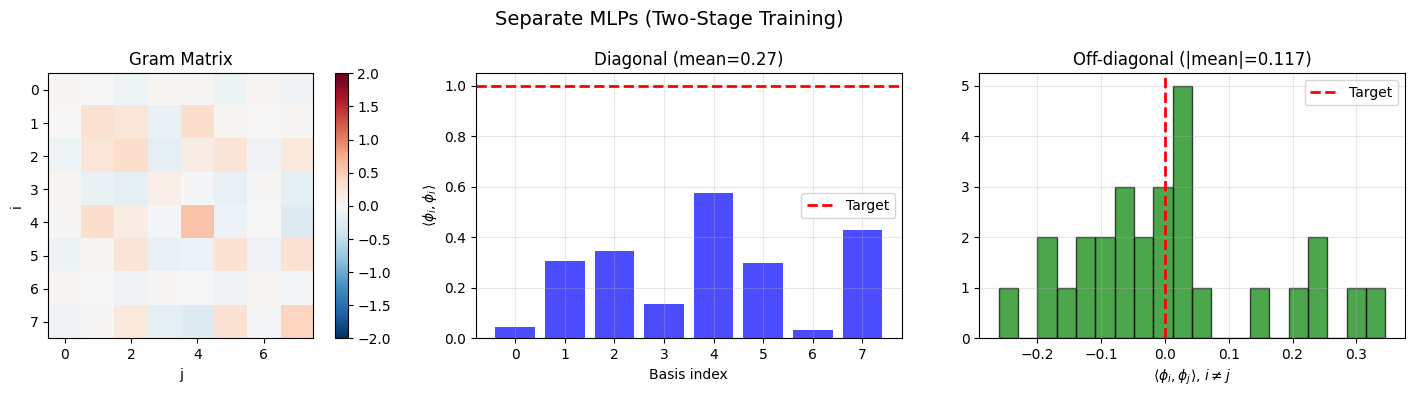

Orthonormality deviation: 2.4059
Diagonal: 0.271 ± 0.177
Off-diagonal: 0.1169


In [33]:
# Compare orthonormality
print("\n" + "="*60)
print("WITHOUT Orthonormalization:")
print("="*60)
plot_gram_analysis(model_separate, x_torch, "Separate MLPs (Standard Training)")

print("\n" + "="*60)
print("WITH Orthonormalization (Two-Stage):")
print("="*60)
plot_gram_analysis(model_ortho, x_torch, "Separate MLPs (Two-Stage Training)")

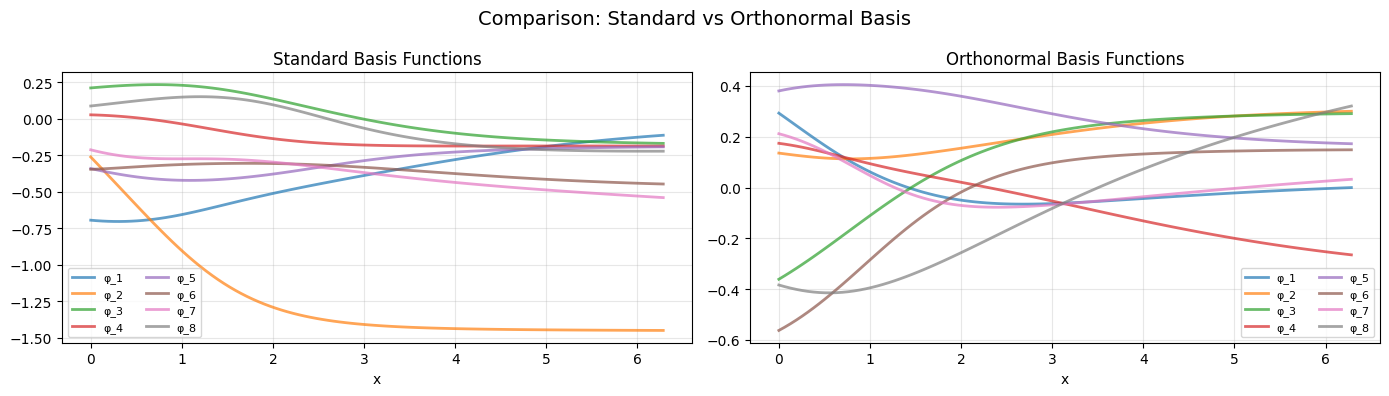

In [34]:
# Compare predictions
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, model, title in [(axes[0], model_separate, 'Standard'),
                          (axes[1], model_ortho, 'Orthonormal')]:
    model.eval()
    with torch.no_grad():
        Phi = model(x_torch).numpy()
    
    for i in range(model.n_basis):
        ax.plot(x_train, Phi[:, i], alpha=0.7, linewidth=2, label=f'φ_{i+1}')
    ax.set_title(f'{title} Basis Functions')
    ax.set_xlabel('x')
    ax.legend(fontsize=8, ncol=2)
    ax.grid(True, alpha=0.3)

plt.suptitle('Comparison: Standard vs Orthonormal Basis', fontsize=14)
plt.tight_layout()
plt.show()

---

## Part 5: Basis Trimming

Use Gram matrix analysis to identify and remove redundant basis functions.

**Strategy:** Trim basis functions to 4 (similar to DeepSets_DeepONet.ipynb example).

In [35]:
def analyze_and_trim_basis(model, x, target_n_basis=4):
    """Trim basis to target number based on Gram matrix quality"""
    G = compute_gram_matrix(model, x)
    n = G.shape[0]
    diag = np.diag(G)
    
    # Score each basis: higher score = better quality
    scores = []
    for i in range(n):
        norm_score = 1.0 - abs(diag[i] - 1.0)
        off_diag_vals = [abs(G[i, j]) for j in range(n) if j != i]
        ortho_score = 1.0 - (max(off_diag_vals) if off_diag_vals else 0)
        scores.append(norm_score + ortho_score)
    
    # Keep top target_n_basis
    keep_indices = np.argsort(scores)[-target_n_basis:]
    keep_indices = sorted(keep_indices)
    
    print(f"Trimming from {n} to {target_n_basis} basis functions")
    print(f"Keeping indices: {keep_indices}")
    print(f"Quality scores: {[f'{scores[i]:.3f}' for i in keep_indices]}")
    
    # Create trimmed model
    model_trimmed = SeparateMLPBasis(n_basis=target_n_basis)
    for new_idx, old_idx in enumerate(keep_indices):
        model_trimmed.networks[new_idx].load_state_dict(
            model.networks[old_idx].state_dict()
        )
    
    return model_trimmed, keep_indices

# Trim standard model to 4 basis
model_trimmed, keep_indices = analyze_and_trim_basis(model_separate, x_torch, target_n_basis=4)

Trimming from 8 to 4 basis functions
Keeping indices: [np.int64(2), np.int64(3), np.int64(4), np.int64(7)]
Quality scores: ['0.919', '-0.061', '-0.598', '0.530']


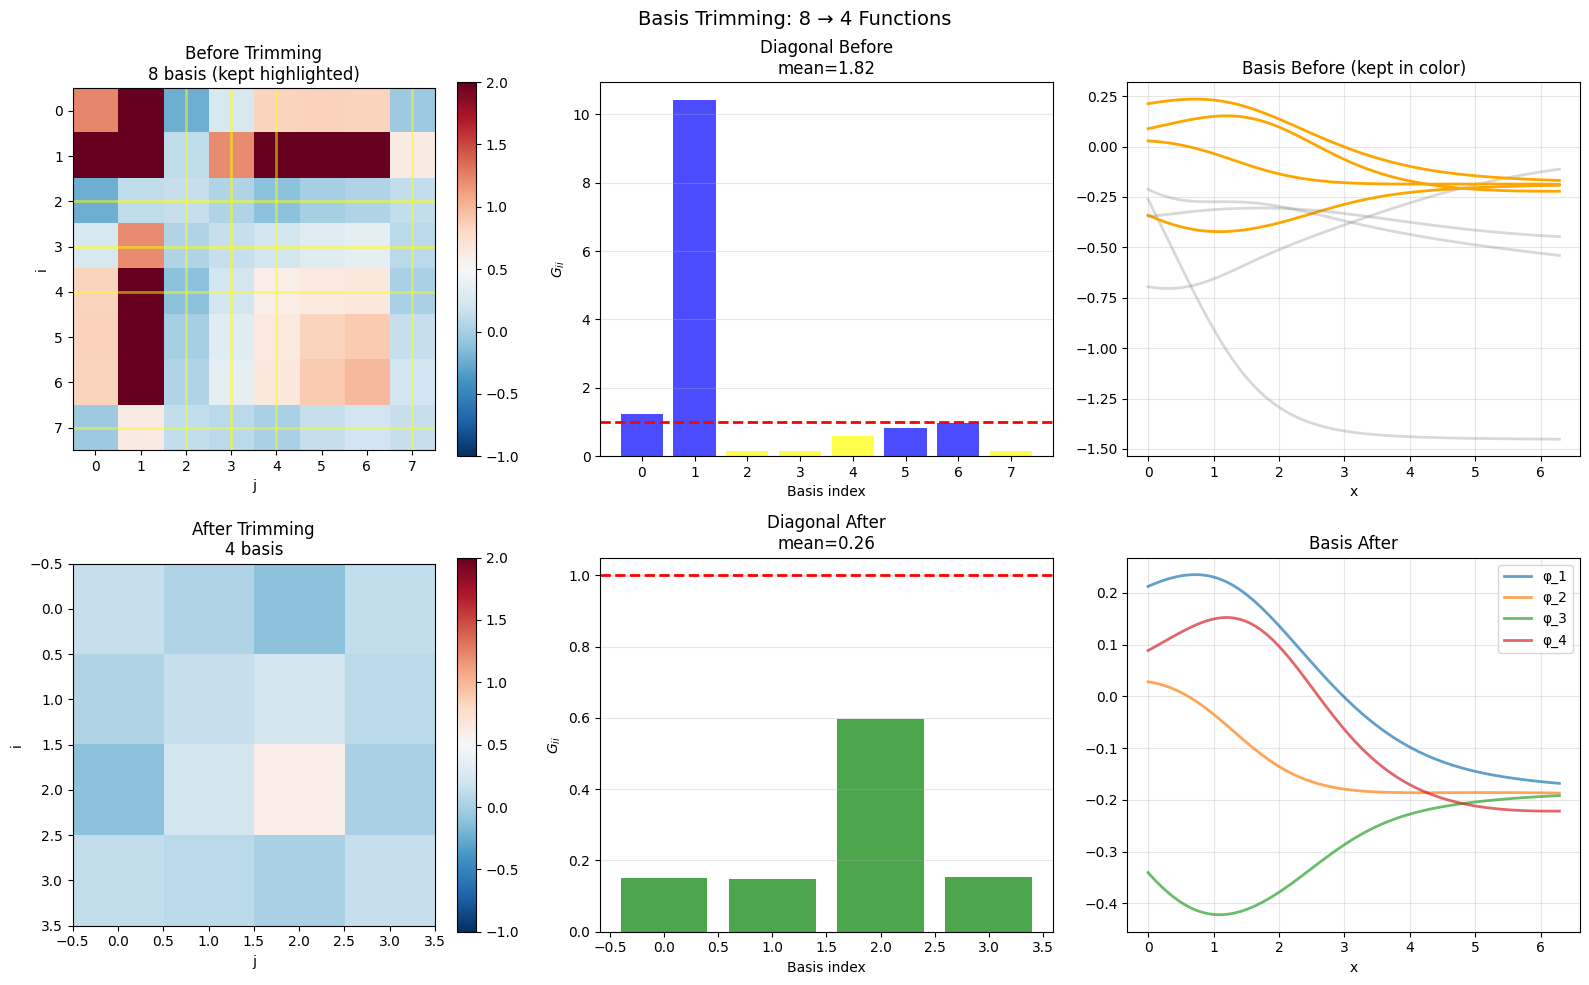

Orthonormality score before: 12.8401
Orthonormality score after: 1.5837
Improvement: 87.7%


In [36]:
# Compare before and after trimming
G_before = compute_gram_matrix(model_separate, x_torch)
G_after = compute_gram_matrix(model_trimmed, x_torch)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# Gram matrices
ax = axes[0, 0]
im = ax.imshow(G_before, cmap='RdBu_r', vmin=-1, vmax=2)
for idx in keep_indices:
    ax.axhline(idx, color='yellow', linewidth=2, alpha=0.5)
    ax.axvline(idx, color='yellow', linewidth=2, alpha=0.5)
ax.set_title(f'Before Trimming\n{model_separate.n_basis} basis (kept highlighted)')
ax.set_xlabel('j')
ax.set_ylabel('i')
plt.colorbar(im, ax=ax)

ax = axes[1, 0]
im = ax.imshow(G_after, cmap='RdBu_r', vmin=-1, vmax=2)
ax.set_title(f'After Trimming\n{model_trimmed.n_basis} basis')
ax.set_xlabel('j')
ax.set_ylabel('i')
plt.colorbar(im, ax=ax)

# Diagonals
ax = axes[0, 1]
diag_before = np.diag(G_before)
colors = ['yellow' if i in keep_indices else 'blue' for i in range(len(diag_before))]
ax.bar(range(len(diag_before)), diag_before, alpha=0.7, color=colors)
ax.axhline(1.0, color='red', linestyle='--', linewidth=2)
ax.set_title(f'Diagonal Before\nmean={diag_before.mean():.2f}')
ax.set_xlabel('Basis index')
ax.set_ylabel('$G_{ii}$')
ax.grid(True, alpha=0.3, axis='y')

ax = axes[1, 1]
diag_after = np.diag(G_after)
ax.bar(range(len(diag_after)), diag_after, alpha=0.7, color='green')
ax.axhline(1.0, color='red', linestyle='--', linewidth=2)
ax.set_title(f'Diagonal After\nmean={diag_after.mean():.2f}')
ax.set_xlabel('Basis index')
ax.set_ylabel('$G_{ii}$')
ax.grid(True, alpha=0.3, axis='y')

# Basis functions
ax = axes[0, 2]
model_separate.eval()
with torch.no_grad():
    Phi_before = model_separate(x_torch).numpy()
for i in range(model_separate.n_basis):
    color = 'orange' if i in keep_indices else 'gray'
    alpha_val = 1.0 if i in keep_indices else 0.3
    ax.plot(x_train, Phi_before[:, i], alpha=alpha_val, linewidth=2, color=color)
ax.set_title('Basis Before (kept in color)')
ax.set_xlabel('x')
ax.grid(True, alpha=0.3)

ax = axes[1, 2]
model_trimmed.eval()
with torch.no_grad():
    Phi_after = model_trimmed(x_torch).numpy()
for i in range(model_trimmed.n_basis):
    ax.plot(x_train, Phi_after[:, i], alpha=0.7, linewidth=2, label=f'φ_{i+1}')
ax.set_title('Basis After')
ax.set_xlabel('x')
ax.legend()
ax.grid(True, alpha=0.3)

plt.suptitle('Basis Trimming: 8 → 4 Functions', fontsize=14)
plt.tight_layout()
plt.show()

ortho_before = np.linalg.norm(G_before - np.eye(model_separate.n_basis), 'fro')
ortho_after = np.linalg.norm(G_after - np.eye(model_trimmed.n_basis), 'fro')
print(f"Orthonormality score before: {ortho_before:.4f}")
print(f"Orthonormality score after: {ortho_after:.4f}")
print(f"Improvement: {((ortho_before - ortho_after) / ortho_before * 100):.1f}%")

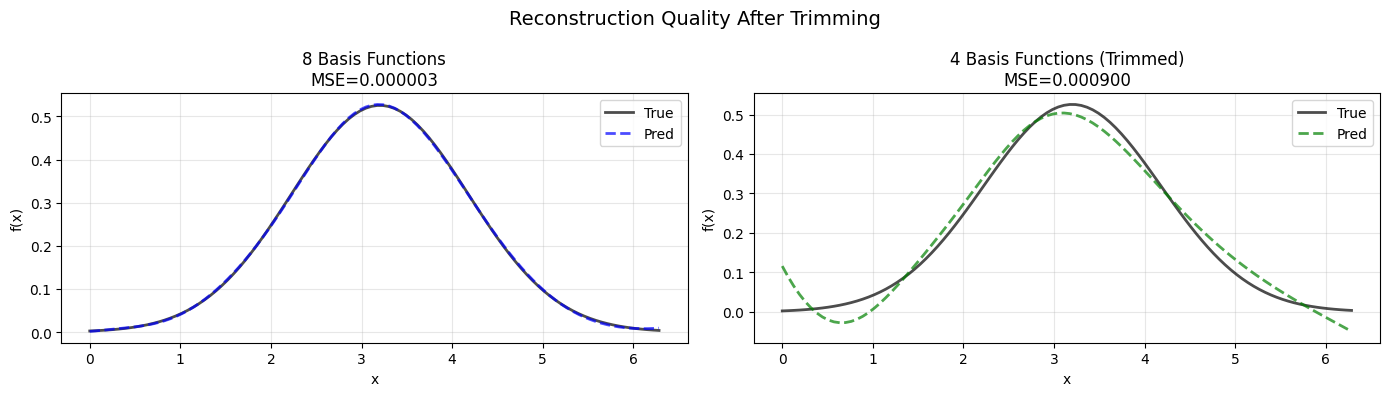


Reconstruction MSE:
  8 basis: 0.00000299
  4 basis: 0.00090001
Trimming maintains good approximation quality with fewer basis!


In [37]:
# Test reconstruction quality
test_idx = 0

model_separate.eval()
model_trimmed.eval()

with torch.no_grad():
    Phi_before = model_separate(x_test_torch)
    PhiT_Phi = Phi_before.T @ Phi_before
    PhiT_f = Phi_before.T @ f_test_torch[test_idx]
    alpha_before = torch.linalg.solve(PhiT_Phi, PhiT_f)
    f_recon_before = (Phi_before @ alpha_before).numpy()
    
    Phi_after = model_trimmed(x_test_torch)
    PhiT_Phi = Phi_after.T @ Phi_after
    PhiT_f = Phi_after.T @ f_test_torch[test_idx]
    alpha_after = torch.linalg.solve(PhiT_Phi, PhiT_f)
    f_recon_after = (Phi_after @ alpha_after).numpy()

mse_before = np.mean((f_test[test_idx] - f_recon_before) ** 2)
mse_after = np.mean((f_test[test_idx] - f_recon_after) ** 2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

ax1.plot(x_test, f_test[test_idx], 'k-', linewidth=2, label='True', alpha=0.7)
ax1.plot(x_test, f_recon_before, 'b--', linewidth=2, label='Pred', alpha=0.7)
ax1.set_title(f'8 Basis Functions\nMSE={mse_before:.6f}')
ax1.set_xlabel('x')
ax1.set_ylabel('f(x)')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(x_test, f_test[test_idx], 'k-', linewidth=2, label='True', alpha=0.7)
ax2.plot(x_test, f_recon_after, 'g--', linewidth=2, label='Pred', alpha=0.7)
ax2.set_title(f'4 Basis Functions (Trimmed)\nMSE={mse_after:.6f}')
ax2.set_xlabel('x')
ax2.set_ylabel('f(x)')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.suptitle('Reconstruction Quality After Trimming', fontsize=14)
plt.tight_layout()
plt.show()

print(f"\nReconstruction MSE:")
print(f"  8 basis: {mse_before:.8f}")
print(f"  4 basis: {mse_after:.8f}")
print(f"Trimming maintains good approximation quality with fewer basis!")

---

## Part 6: Nested Bases with a Matryoshka Loss

Part 5 trimmed the basis after training. The score ranked the eight functions by their Gram matrix entries, and the printed test error shows what the trimmed basis lost. The basis was never trained to be trimmed, so no ordering of its functions is guaranteed to work.

A Matryoshka loss (Kusupati et al., 2022, introduced for embeddings) trains every prefix of the basis at once. For each $k = 1, \dots, d$, fit the family with the first $k$ basis functions only,

$$\alpha^{(k)}_n = \arg\min_{\alpha \in \mathbb{R}^k} \Big\| f_n - \sum_{j=1}^k \alpha_j \phi_j \Big\|^2, \qquad L_k = \frac{1}{N} \sum_{n=1}^N \Big\| f_n - \sum_{j=1}^k \alpha^{(k)}_{n,j} \phi_j \Big\|^2,$$

and minimize all $L_k$ together. Then $\phi_1$ must be the best single function for the family, $\{\phi_1, \phi_2\}$ the best pair that contains $\phi_1$, and so on. Trimming to $k$ functions means dropping the tail, and the cost of trimming is $L_k$.

The errors $L_k$ fall by orders of magnitude from $k = 1$ to $k = 8$, so the plain mean $\frac{1}{d}\sum_k L_k$ is dominated by the first terms and leaves the full basis undertrained. The mean of $\log L_k$ weights every prefix by its relative change and minimizes the product of the prefix errors. The table below trains both.

The minimizer of each $L_k$ over all $k$-dimensional subspaces is known. Stack the training functions on the grid as rows of $F \in \mathbb{R}^{N \times m}$ and take the SVD $F = U S V^\top$. The first $k$ right singular vectors $v_1, \dots, v_k$ span the subspace with the smallest mean-square error, which equals $\sum_{j > k} s_j^2 / (N m)$. This is the proper orthogonal decomposition (POD) of the family. The POD subspaces are nested, so one basis minimizes every $L_k$ at once, namely any basis whose first $k$ functions span $\{v_1, \dots, v_k\}$ for each $k$. The Matryoshka loss asks the networks to learn the POD modes, up to a triangular change of basis within each prefix, as functions of $x$ that can be evaluated anywhere. The POD error is the lower bound for every curve below.

In [19]:
def matryoshka_loss(model, x, f, sizes, weighting='log'):
    """Least-squares error of every basis prefix in sizes, combined by the mean or by the mean of logs"""
    Phi = model(x)
    errors = []
    for k in sizes:
        P = Phi[:, :k]
        alpha = torch.linalg.solve(P.T @ P, P.T @ f.T)
        errors.append(torch.mean((f.T - P @ alpha) ** 2))
    errors = torch.stack(errors)
    return torch.log(errors).mean() if weighting == 'log' else errors.mean()

def train_matryoshka(model, x, f, sizes, weighting='log', n_epochs=2000, lr=1e-3):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    losses = []
    for epoch in tqdm(range(n_epochs), desc=f"Training ({weighting})"):
        model.train()
        loss = matryoshka_loss(model, x, f, sizes, weighting)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return losses

n_epochs = 2000
sizes = list(range(1, 9))

torch.manual_seed(0)
model_long = SeparateMLPBasis(n_basis=8)
losses_long = train_function_encoder(model_long, x_torch, f_torch, n_epochs=n_epochs)

torch.manual_seed(0)
model_matry_mean = SeparateMLPBasis(n_basis=8)
losses_matry_mean = train_matryoshka(model_matry_mean, x_torch, f_torch, sizes, weighting='mean', n_epochs=n_epochs)

torch.manual_seed(0)
model_matry = SeparateMLPBasis(n_basis=8)
losses_matry = train_matryoshka(model_matry, x_torch, f_torch, sizes, weighting='log', n_epochs=n_epochs)

print(f"Standard, {n_epochs} epochs, final MSE: {losses_long[-1]:.3e}")
print(f"Matryoshka (mean), final loss: {losses_matry_mean[-1]:.3e}")
print(f"Matryoshka (log), final loss: {losses_matry[-1]:.3f}")

Training (log): 100%|██████████| 2000/2000 [00:12<00:00, 154.70it/s]

Standard, 2000 epochs, final MSE: 5.505e-03
Matryoshka (mean), final loss: 1.733e-02
Matryoshka (log), final loss: -5.846


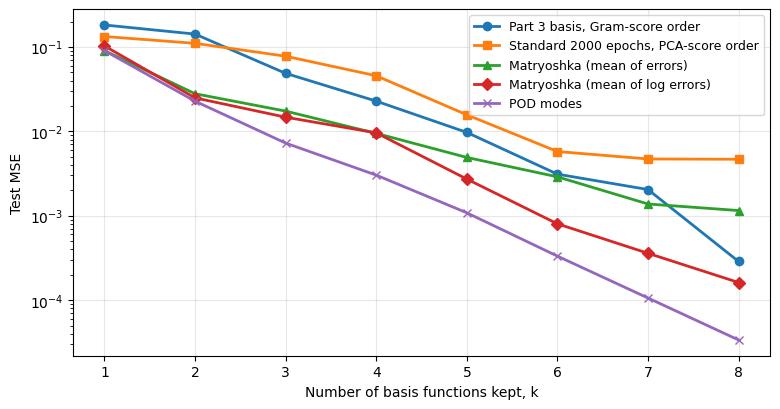

A: Part 3 basis, Gram-score order
B: Standard 2000 epochs, PCA-score order
C: Matryoshka (mean of errors)
D: Matryoshka (mean of log errors)
E: POD modes
 k           A           B           C           D           E
 1    1.82e-01    1.33e-01    9.03e-02    1.03e-01    9.03e-02
 2    1.42e-01    1.10e-01    2.79e-02    2.49e-02    2.28e-02
 3    4.86e-02    7.76e-02    1.74e-02    1.47e-02    7.25e-03
 4    2.28e-02    4.55e-02    9.46e-03    9.59e-03    3.03e-03
 5    9.71e-03    1.57e-02    4.90e-03    2.72e-03    1.08e-03
 6    3.11e-03    5.76e-03    2.89e-03    8.02e-04    3.32e-04
 7    2.04e-03    4.70e-03    1.38e-03    3.59e-04    1.06e-04
 8    2.87e-04    4.67e-03    1.15e-03    1.62e-04    3.37e-05


In [20]:
def prefix_mse(model, x, f, order, k):
    """Test MSE of the least-squares fit with the k basis functions order[:k]"""
    model.eval()
    with torch.no_grad():
        P = model(x)[:, order[:k]]
        alpha = torch.linalg.solve(P.T @ P, P.T @ f.T)
        return torch.mean((f.T - P @ alpha) ** 2).item()

def gram_score_order(model, x):
    """Ordering by the Part 5 score: diagonal near 1 and small off-diagonal entries"""
    G = compute_gram_matrix(model, x)
    n = G.shape[0]
    scores = [(1.0 - abs(G[i, i] - 1.0)) + (1.0 - max(abs(G[i, j]) for j in range(n) if j != i)) for i in range(n)]
    return list(np.argsort(scores)[::-1])

def pca_score_order(model, x, f, k):
    """Train-then-prune ordering (Low et al., 2025): score basis p by sum_{i<=k} lambda_i U_{pi}^2 of the coefficient covariance"""
    model.eval()
    with torch.no_grad():
        Phi = model(x)
        C = torch.linalg.solve(Phi.T @ Phi, Phi.T @ f.T).T.numpy()
    lam, U = np.linalg.eigh(np.cov(C, rowvar=False))
    lam, U = lam[::-1], U[:, ::-1]
    scores = (lam[:k] * U[:, :k] ** 2).sum(axis=1)
    return list(np.argsort(scores)[::-1])

# POD of the training family: the best k-dimensional subspace for each k
_, S_pod, Vt_pod = np.linalg.svd(f_train, full_matrices=False)

def pod_mse(k):
    V = Vt_pod[:k].T
    return np.mean((f_test - f_test @ V @ V.T) ** 2)

ks = list(range(1, 9))
index_order = list(range(8))
mse = {
    'Part 3 basis, Gram-score order': [prefix_mse(model_separate, x_test_torch, f_test_torch, gram_score_order(model_separate, x_torch), k) for k in ks],
    f'Standard {n_epochs} epochs, PCA-score order': [prefix_mse(model_long, x_test_torch, f_test_torch, pca_score_order(model_long, x_torch, f_torch, k), k) for k in ks],
    'Matryoshka (mean of errors)': [prefix_mse(model_matry_mean, x_test_torch, f_test_torch, index_order, k) for k in ks],
    'Matryoshka (mean of log errors)': [prefix_mse(model_matry, x_test_torch, f_test_torch, index_order, k) for k in ks],
    'POD modes': [pod_mse(k) for k in ks],
}

plt.figure(figsize=(9, 4.5))
for (name, vals), marker in zip(mse.items(), ['o', 's', '^', 'D', 'x']):
    plt.plot(ks, vals, marker=marker, linewidth=2, label=name)
plt.xlabel('Number of basis functions kept, k')
plt.ylabel('Test MSE')
plt.yscale('log')
plt.legend(fontsize=9)
plt.grid(True, alpha=0.3)
plt.show()

labels = ['A', 'B', 'C', 'D', 'E']
for label, name in zip(labels, mse):
    print(f"{label}: {name}")
print(f"{'k':>2}" + "".join(f"{label:>12s}" for label in labels))
for i, k in enumerate(ks):
    print(f"{k:>2}" + "".join(f"{mse[name][i]:>12.2e}" for name in mse))

Largest principal angle (degrees) between the first k basis functions and the first k POD modes
 k    Matryoshka (log)   Standard, index order
 1                11.6                    27.5
 2                 8.4                    35.8
 3                35.4                    57.5
 4                35.3                    84.0
 5                29.3                    84.0
 6                31.1                    86.3
 7                28.7                    88.6
 8                39.8                    88.7


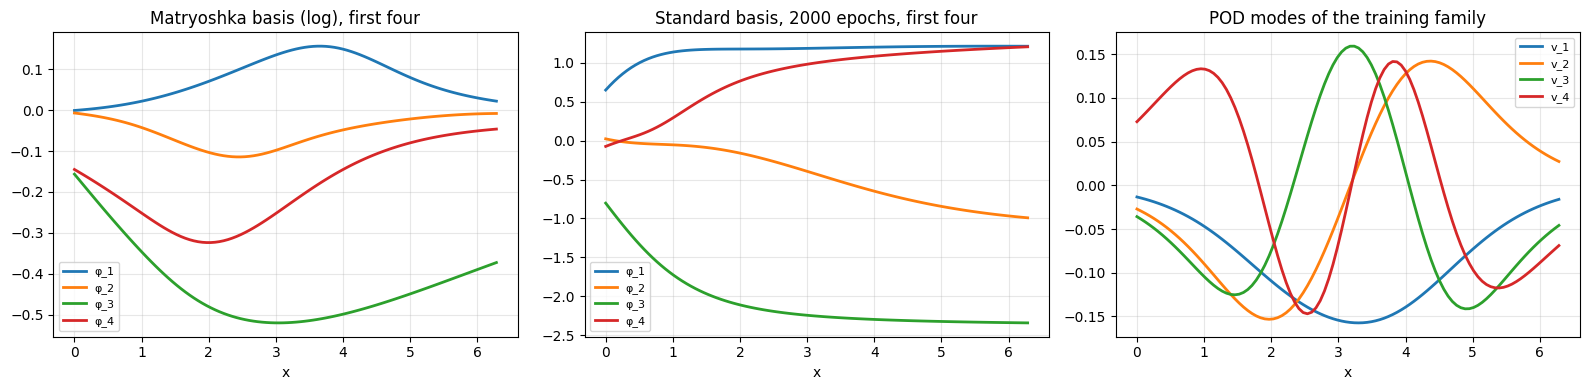

In [21]:
def largest_principal_angle(A, B):
    """Largest principal angle in degrees between the column spaces of A and B"""
    Qa, _ = np.linalg.qr(A)
    Qb, _ = np.linalg.qr(B)
    cosines = np.clip(np.linalg.svd(Qa.T @ Qb, compute_uv=False), -1.0, 1.0)
    return np.degrees(np.arccos(cosines.min()))

model_matry.eval()
model_long.eval()
with torch.no_grad():
    Phi_matry = model_matry(x_torch).numpy()
    Phi_long = model_long(x_torch).numpy()

print("Largest principal angle (degrees) between the first k basis functions and the first k POD modes")
print(f"{'k':>2}{'Matryoshka (log)':>20}{'Standard, index order':>24}")
for k in ks:
    print(f"{k:>2}{largest_principal_angle(Phi_matry[:, :k], Vt_pod[:k].T):>20.1f}{largest_principal_angle(Phi_long[:, :k], Vt_pod[:k].T):>24.1f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i in range(4):
    axes[0].plot(x_train, Phi_matry[:, i], linewidth=2, label=f'φ_{i+1}')
    axes[1].plot(x_train, Phi_long[:, i], linewidth=2, label=f'φ_{i+1}')
    axes[2].plot(x_train, Vt_pod[i], linewidth=2, label=f'v_{i+1}')
axes[0].set_title('Matryoshka basis (log), first four')
axes[1].set_title(f'Standard basis, {n_epochs} epochs, first four')
axes[2].set_title('POD modes of the training family')
for ax in axes:
    ax.set_xlabel('x')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Row E, the POD modes, is the lower bound for any basis of $k$ functions. The Matryoshka basis trained on the mean of log errors (row D) stays within a factor of five of that bound at every $k$, and within 15 percent at $k = 1$ and $k = 2$ ($1.03 \times 10^{-1}$ against $9.03 \times 10^{-2}$, then $2.49 \times 10^{-2}$ against $2.28 \times 10^{-2}$). Its error falls at every added function and ends at $1.62 \times 10^{-4}$ for the full basis. The mean of errors (row C) matches POD at $k = 1$ and then flattens, ending at $1.15 \times 10^{-3}$, because the large early terms dominate the sum. The standard basis has no ordering. Ranked by the train-then-prune score (row B), its first four functions give $4.55 \times 10^{-2}$, fifteen times the POD value $3.03 \times 10^{-3}$ and nearly five times the Matryoshka value $9.59 \times 10^{-3}$. The Gram-score ranking of the Part 3 basis (row A) gives $2.28 \times 10^{-2}$ at $k = 4$.

The principal angles say the same thing in geometric terms. The first Matryoshka function is $11.6^\circ$ from the first POD mode, and the first two span a plane $8.4^\circ$ from the POD plane, while the first four standard functions are $84.0^\circ$ from the four-dimensional POD subspace. The learned prefixes approximate the POD subspaces, and the remaining angle is the optimization error of the networks. The basis plot shows the consequence. The first Matryoshka functions are a bump, a shifted dip, and two wider shapes, which combine the POD modes through a triangular change of basis, while the standard functions are monotone ramps that saturate and encode the family in their differences.

The standard loss also trains erratically. The 2000-epoch run (row B) ends at $4.67 \times 10^{-3}$ for the full basis, above the $2.87 \times 10^{-4}$ of the 200-epoch run of Part 3, which is consistent with the ill-conditioned Gram matrices measured in Part 4. The Matryoshka basis ends lower than both at the full width.

---

## Part 7: Linearity of Coefficients in Hilbert Space

**Key property:** In a Hilbert space with basis $\{\phi_j\}$, coefficients preserve linear structure.

For functions $f_1, f_2 \in \mathcal{H}$ with coefficients $\alpha^{(1)}, \alpha^{(2)}$:

$$f_1(x) = \sum_j \alpha_j^{(1)} \phi_j(x), \quad f_2(x) = \sum_j \alpha_j^{(2)} \phi_j(x)$$

**Linear combination:**

$$f_3 = a f_1 + b f_2 \quad \Rightarrow \quad \alpha^{(3)} = a \alpha^{(1)} + b \alpha^{(2)}$$

This enables **composition** of functions in coefficient space without recomputing basis.

**Application:** Transfer learning, function interpolation, operator learning.

Linearity of Coefficients in Hilbert Space
f₃ = 0.5f₁ + 0.5f₂       : MSE = 0.00001040
f₃ = 0.7f₁ + 0.3f₂       : MSE = 0.00008085
f₃ = f₁ - 0.5f₂          : MSE = 0.00145489
f₃ = 2f₁ + f₂            : MSE = 0.00048657


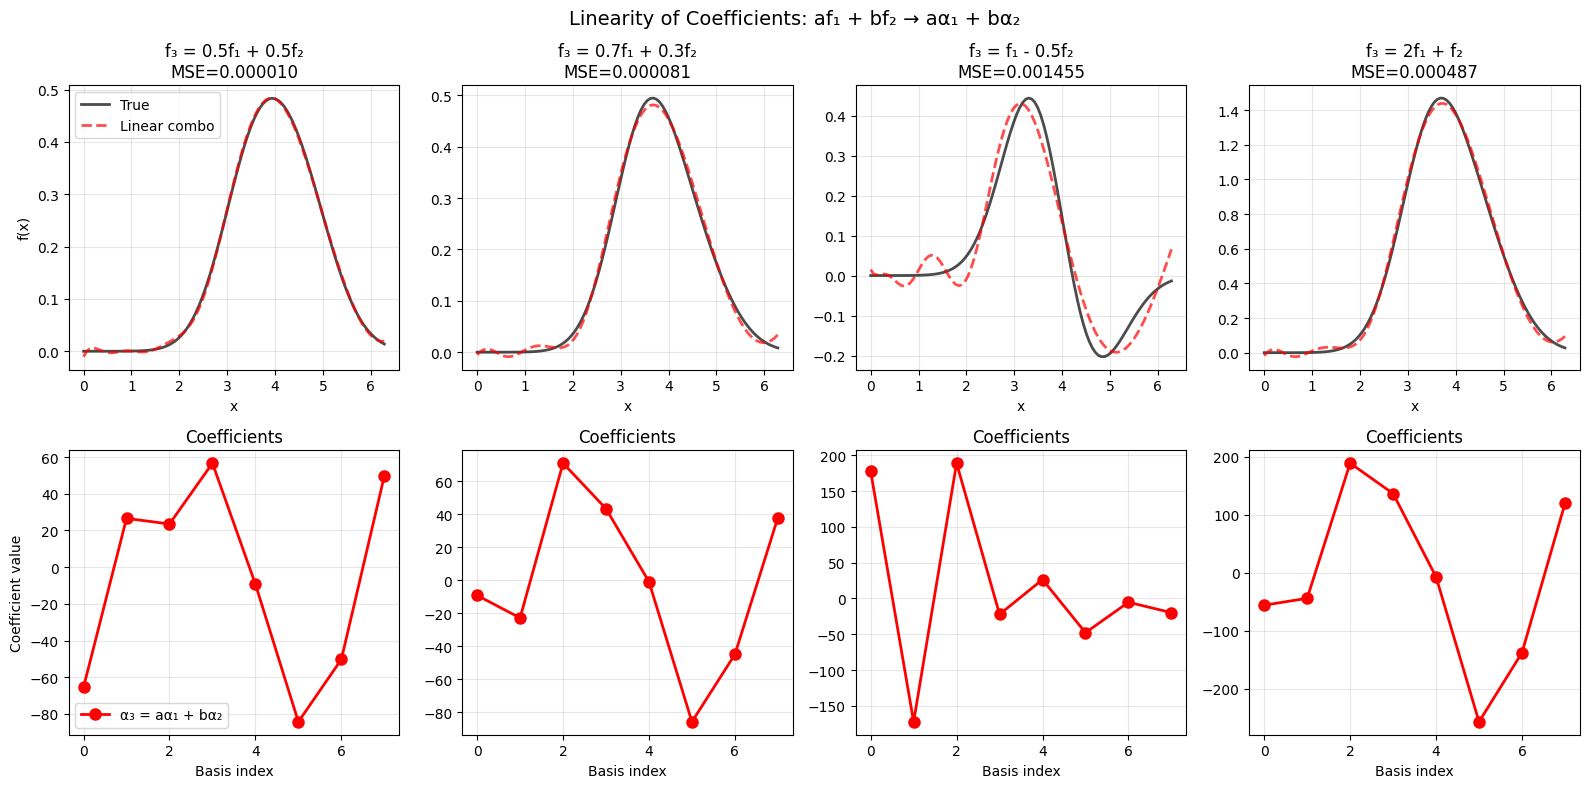


Linear structure in coefficient space enables function composition!


In [38]:
# Demonstrate linearity of coefficients
print("Linearity of Coefficients in Hilbert Space")
print("="*60)

# Select two base functions
f1_idx, f2_idx = 10, 50
f1 = f_train[f1_idx]
f2 = f_train[f2_idx]

# Get coefficients using orthonormal model
model_ortho.eval()
with torch.no_grad():
    Phi_train = model_ortho(x_torch)
    PhiT_Phi = Phi_train.T @ Phi_train
    
    PhiT_f1 = Phi_train.T @ torch.FloatTensor(f1)
    alpha1 = torch.linalg.solve(PhiT_Phi, PhiT_f1).numpy()
    
    PhiT_f2 = Phi_train.T @ torch.FloatTensor(f2)
    alpha2 = torch.linalg.solve(PhiT_Phi, PhiT_f2).numpy()

# Test linear combinations
test_combos = [
    (0.5, 0.5, "f₃ = 0.5f₁ + 0.5f₂"),
    (0.7, 0.3, "f₃ = 0.7f₁ + 0.3f₂"),
    (1.0, -0.5, "f₃ = f₁ - 0.5f₂"),
    (2.0, 1.0, "f₃ = 2f₁ + f₂")
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for col, (a, b, name) in enumerate(test_combos):
    # True function via linear combination
    f_true = a * f1 + b * f2
    
    # Predicted coefficients via linearity
    alpha_pred = a * alpha1 + b * alpha2
    
    # Reconstruct
    with torch.no_grad():
        f_recon = (Phi_train @ torch.FloatTensor(alpha_pred)).numpy()
    
    mse = np.mean((f_true - f_recon) ** 2)
    
    # Plot functions
    ax = axes[0, col]
    ax.plot(x_train, f_true, 'k-', linewidth=2, label='True', alpha=0.7)
    ax.plot(x_train, f_recon, 'r--', linewidth=2, label='Linear combo', alpha=0.7)
    ax.set_title(f'{name}\nMSE={mse:.6f}')
    ax.set_xlabel('x')
    if col == 0:
        ax.set_ylabel('f(x)')
        ax.legend()
    ax.grid(True, alpha=0.3)
    
    # Plot coefficients
    ax = axes[1, col]
    indices = np.arange(len(alpha1))
    ax.plot(indices, alpha_pred, 'ro-', linewidth=2, markersize=8, label='α₃ = aα₁ + bα₂')
    ax.set_title(f'Coefficients')
    ax.set_xlabel('Basis index')
    if col == 0:
        ax.set_ylabel('Coefficient value')
        ax.legend()
    ax.grid(True, alpha=0.3)
    
    print(f"{name:25s}: MSE = {mse:.8f}")

plt.suptitle('Linearity of Coefficients: af₁ + bf₂ → aα₁ + bα₂', fontsize=14)
plt.tight_layout()
plt.show()

print("\nLinear structure in coefficient space enables function composition!")

---

## Part 8: Guarantees at Inference Time

After training, the basis is frozen. A new function $f$ arrives as $m$ samples $(x_i, y_i)$, and the only computation left is a ridge regression in the fixed basis,

$$\hat\alpha = (\Phi^\top \Phi + \lambda I)^{-1} \Phi^\top y, \qquad \Phi_{ij} = \phi_j(x_i), \qquad \hat f(x) = \sum_{j=1}^k \hat\alpha_j \phi_j(x).$$

Evaluating $\hat f$ at a new point costs $k$ basis evaluations, whatever $m$ was. A kernel method with the kernel $\kappa(x, x') = \langle \varphi(x), \varphi(x') \rangle$, where $\varphi(x) = (\phi_1(x), \dots, \phi_k(x))$, produces the same predictor through an $m \times m$ linear system and an $O(m)$ evaluation. The function encoder is the primal form of this kernel method with an explicit, learned feature map (Low et al., 2025, Proposition 1). Because inference is ridge regression in a $k$-dimensional feature space, the guarantees of kernel ridge regression apply. Two of them matter in practice.

The first is a finite-sample prediction guarantee. Suppose the $m$ samples are independent draws from the distribution we will be tested on, each basis function is bounded by $R$, and the outputs by $Y$. Then with probability at least $1 - \delta$ the population risk $L(\hat f) = \mathbb{E}\,(\hat f(x) - y)^2$ and the empirical risk $\hat L_m(\hat f)$ on the $m$ samples satisfy

$$L(\hat f) \lesssim \hat L_m(\hat f) + \tilde O\!\left(\frac{Y^2 R^2 k}{\lambda \sqrt m}\right)$$

(Low et al., 2025, Theorem 1, by Rademacher complexity, with the loss normalized as $\frac{1}{m}\sum_i (\hat f(x_i) - y_i)^2 + \lambda \|\alpha\|^2$). A PAC-Bayes argument gives the same form with $k^{3/2}$ in place of $k$ (their Theorem 2). Every quantity on the right is known after the fit, so the inequality is a certificate on the error of the new function. The gap grows with the number of basis functions, shrinks as $m^{-1/2}$, and shrinks with the ridge parameter. The experiment below measures the gap for one new function as $m$ grows. The theorem gives a worst-case rate, and the measured gap falls faster.

The second concerns noisy observations. Let the samples be $\tilde y = y + \varepsilon$ and let $\Phi = U \Sigma V^\top$ be the SVD of the design matrix. The change in the coefficients is linear in the noise,

$$\tilde\alpha - \hat\alpha = (\Phi^\top\Phi + \lambda I)^{-1}\Phi^\top \varepsilon = V\,(\Sigma^2 + \lambda I)^{-1}\Sigma\, U^\top \varepsilon,
\qquad
\|\tilde\alpha - \hat\alpha\|_2 \le \Big(\max_i \frac{\sigma_i}{\sigma_i^2 + \lambda}\Big)\,\|\varepsilon\|_2 .$$

With $M = \max_j \sup_x |\phi_j(x)|$ and $\|\cdot\|_1 \le \sqrt k\,\|\cdot\|_2$, the change in the function is bounded at every point,

$$\sup_x |\tilde f(x) - \hat f(x)| \le M \sqrt k \left(\max_i \frac{\sigma_i}{\sigma_i^2 + \lambda}\right) \|\varepsilon\|_2 .$$

Without regularization the factor in parentheses is $1/\sigma_{\min}$, the inverse of the smallest singular value of $\Phi$, which is the square root of the smallest eigenvalue of the Gram matrix from Part 4. Nearly dependent basis functions amplify noise, and few samples make $\Phi$ nearly rank deficient. With $\lambda > 0$ the factor is at most $1/(2\sqrt\lambda)$ for any basis. The table below checks both inequalities with $m = 12$ samples of one new function and the eight-function basis from Part 3.

m = 12 online samples, noise std 0.01, 500 noise draws, basis from Part 3 (k = 8)
  lambda  sigma_min  coef bound  coef measured  sup bound  sup measured
   0e+00    6.1e-05     16283.4         3892.2    63856.2         10.64
   1e-04    6.1e-05        49.9           39.2      195.7          1.79
   1e-02    6.1e-05         4.5            3.9       17.8          0.83
   1e+00    6.1e-05         0.5            0.4        2.0          0.30


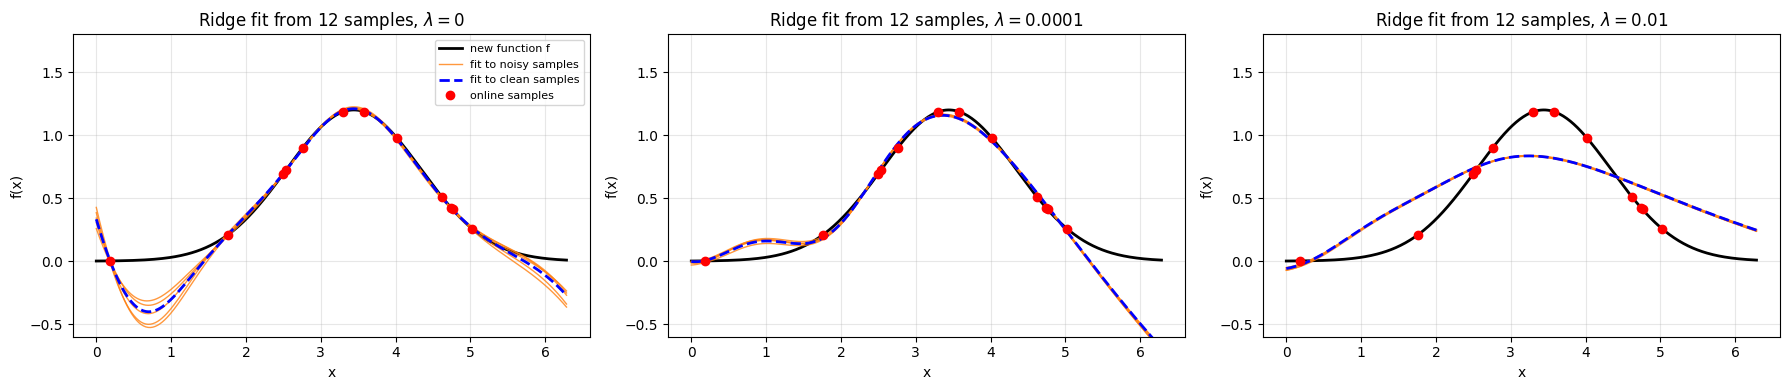

In [23]:
def ridge_coefficients(Phi, y, lam):
    return torch.linalg.solve(Phi.T @ Phi + lam * torch.eye(Phi.shape[1]), Phi.T @ y)

def noise_amplification(model, x_m, y_m, x_dense, lam, noise_std=0.01, n_trials=500):
    """Bounds and measured amplification of observation noise, in the coefficients and in the function values"""
    model.eval()
    with torch.no_grad():
        Phi_m, Phi_dense = model(x_m), model(x_dense)
        sigma = torch.linalg.svdvals(Phi_m)
        M, k = Phi_dense.abs().max().item(), Phi_m.shape[1]
        coef_bound = torch.max(sigma / (sigma ** 2 + lam)).item()
        alpha = ridge_coefficients(Phi_m, y_m, lam)
        coef_ratio, sup_ratio = [], []
        for _ in range(n_trials):
            eps = noise_std * torch.randn_like(y_m)
            d_alpha = ridge_coefficients(Phi_m, y_m + eps, lam) - alpha
            coef_ratio.append(d_alpha.norm().item() / eps.norm().item())
            sup_ratio.append((Phi_dense @ d_alpha).abs().max().item() / eps.norm().item())
    return dict(sigma_min=sigma.min().item(), coef_bound=coef_bound, coef_measured=max(coef_ratio),
                sup_bound=M * np.sqrt(k) * coef_bound, sup_measured=max(sup_ratio))

torch.manual_seed(1)
m_online = 12
x_online = torch.sort(torch.rand(m_online) * 2 * np.pi).values
f_new = lambda x: target_function(x, center=np.pi + 0.3, width=0.9, amplitude=1.2)
y_online = torch.FloatTensor(f_new(x_online.numpy()))
x_dense = torch.linspace(0, 2 * np.pi, 400)

print(f"m = {m_online} online samples, noise std 0.01, 500 noise draws, basis from Part 3 (k = 8)")
print(f"{'lambda':>8}{'sigma_min':>11}{'coef bound':>12}{'coef measured':>15}{'sup bound':>11}{'sup measured':>14}")
for lam in [0.0, 1e-4, 1e-2, 1.0]:
    r = noise_amplification(model_separate, x_online, y_online, x_dense, lam)
    print(f"{lam:>8.0e}{r['sigma_min']:>11.1e}{r['coef_bound']:>12.1f}{r['coef_measured']:>15.1f}{r['sup_bound']:>11.1f}{r['sup_measured']:>14.2f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
model_separate.eval()
with torch.no_grad():
    Phi_m, Phi_dense = model_separate(x_online), model_separate(x_dense)
    for ax, lam in zip(axes, [0.0, 1e-4, 1e-2]):
        ax.plot(x_dense, f_new(x_dense.numpy()), 'k-', linewidth=2, label='new function f')
        torch.manual_seed(2)
        for t in range(5):
            eps = 0.01 * torch.randn_like(y_online)
            ax.plot(x_dense, Phi_dense @ ridge_coefficients(Phi_m, y_online + eps, lam), color='tab:orange',
                    linewidth=1, alpha=0.8, label='fit to noisy samples' if t == 0 else None)
        ax.plot(x_dense, Phi_dense @ ridge_coefficients(Phi_m, y_online, lam), 'b--', linewidth=2, label='fit to clean samples')
        ax.plot(x_online, y_online, 'ro', markersize=6, zorder=6, label='online samples')
        ax.set_title(rf'Ridge fit from {m_online} samples, $\lambda = {lam:g}$')
        ax.set_xlabel('x')
        ax.set_ylabel('f(x)')
        ax.set_ylim(-0.6, 1.8)
        ax.grid(True, alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

lambda = 0.001, noise std 0.05, 200 trials per m
m:            8        16        32        64       128       256       512
gap:   7.44e-02  2.25e-02  8.10e-03  4.65e-03  1.74e-03  3.29e-04  2.27e-04


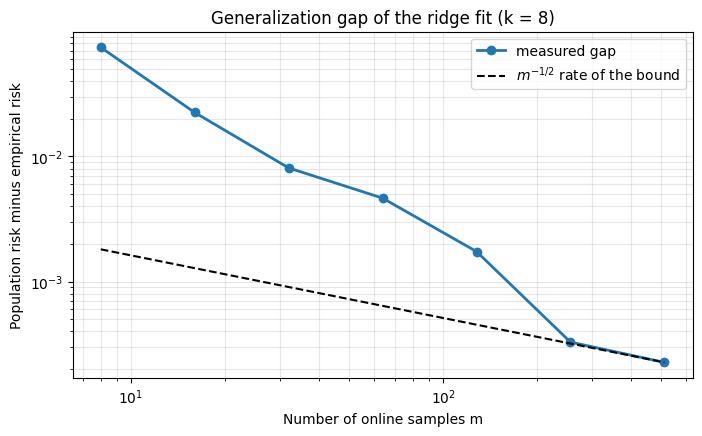

In [24]:
def generalization_gap(model, f_fn, m, lam, noise_std=0.05, n_trials=200):
    """Population risk minus empirical risk of the ridge fit from m noisy samples, mean over trials"""
    model.eval()
    x_pop = torch.linspace(0, 2 * np.pi, 400)
    with torch.no_grad():
        Phi_pop = model(x_pop)
        f_pop = torch.FloatTensor(f_fn(x_pop.numpy()))
        gaps = []
        for _ in range(n_trials):
            x_m = torch.rand(m) * 2 * np.pi
            y_m = torch.FloatTensor(f_fn(x_m.numpy())) + noise_std * torch.randn(m)
            Phi_m = model(x_m)
            alpha = ridge_coefficients(Phi_m, y_m, m * lam)  # loss normalized as (1/m) sum + lam |alpha|^2
            empirical = torch.mean((Phi_m @ alpha - y_m) ** 2).item()
            population = torch.mean((Phi_pop @ alpha - f_pop) ** 2).item() + noise_std ** 2
            gaps.append(population - empirical)
    return np.mean(gaps)

torch.manual_seed(0)
ms = [8, 16, 32, 64, 128, 256, 512]
lam = 1e-3
gaps = [generalization_gap(model_separate, f_new, m, lam) for m in ms]
print(f"lambda = {lam:g}, noise std 0.05, 200 trials per m")
print("m:   " + "".join(f"{m:>10d}" for m in ms))
print("gap: " + "".join(f"{g:>10.2e}" for g in gaps))

plt.figure(figsize=(8, 4.5))
plt.loglog(ms, gaps, 'o-', linewidth=2, label='measured gap')
plt.loglog(ms, [gaps[-1] * np.sqrt(ms[-1] / m) for m in ms], 'k--', label=r'$m^{-1/2}$ rate of the bound')
plt.xlabel('Number of online samples m')
plt.ylabel('Population risk minus empirical risk')
plt.title('Generalization gap of the ridge fit (k = 8)')
plt.legend()
plt.grid(True, alpha=0.3, which='both')
plt.show()

With twelve samples the design matrix has smallest singular value $6.1 \times 10^{-5}$. Without regularization the coefficient bound is $1.6 \times 10^{4}$, and the measured worst case over 500 noise draws is $3.9 \times 10^{3}$, so noise of norm $\|\varepsilon\|_2 = 0.01\sqrt{12} \approx 0.035$ moves the coefficient vector by about $3.9 \times 10^{3} \times 0.035 \approx 135$. The function values move far less, by at most $10.6\,\|\varepsilon\|_2$, because the large coefficient changes cancel where the basis functions are evaluated. The left panel shows where they do not cancel. Between the first sample at $x \approx 0.2$ and the next at $x \approx 1.7$ the noisy fits fan out, and the clean fit itself dips to $-0.4$ there, since twelve samples leave the eight coefficients free in that gap. The coefficient bound is close to the measurement at every $\lambda$, within a factor between 1.2 and 4.2, while the function-value bound is conservative by a factor between 7 and 6000, since it assumes the worst alignment of all eight basis functions at one point.

Regularization trades this sensitivity for bias. At $\lambda = 10^{-4}$ the measured amplification of the function values drops from 10.6 to 1.79, the noisy fits in the middle panel lie on top of the clean one, and the fit follows $f$ on the sampled interval, but beyond the last sample at $x \approx 5$ it leaves $f$, because no sample constrains it there and the ridge has changed which combination of basis functions fills the gap. At $\lambda = 10^{-2}$ the amplification is 0.83, and the right panel shows the price, a fit that reaches 0.85 at the peak of a function of height 1.2 because the ridge shrinks every coefficient. The bound says how much noise a given $\lambda$ lets through. It does not say how much signal the same $\lambda$ removes, and the figure does.

The generalization gap falls from $7.4 \times 10^{-2}$ at $m = 8$ to $2.3 \times 10^{-4}$ at $m = 512$, a factor of about 330. Theorem 1 guarantees a decrease like $m^{-1/2}$, a factor of 8 over the same range. The guarantee holds with room to spare, which is the usual relation between a worst-case bound and one well-behaved function.

---

## Summary

### Key Concepts

1. **Function Encoders**
   - Represent functions as $f(x) = \sum_j \alpha_j \phi_j(x)$ where $\{\phi_j\}$ are **learned** using neural networks
   - Adapt to function families, more efficient than fixed bases

2. **Computing Coefficients**
   - **Least Squares:** $\alpha = (\Phi^T \Phi)^{-1} \Phi^T f$ (works for any basis)
   - **Monte Carlo:** $\alpha_i \approx (V/N) \sum_k f(x_k) \phi_i(x_k)$ (requires orthonormal basis)

3. **Gram Matrix and Orthonormality**
   - Gram matrix $G_{ij} = \langle \phi_i, \phi_j \rangle$ measures basis quality
   - Two-stage training: enforce $G \approx I$ then fine-tune
   - Orthonormal bases have stable, efficient coefficient computation

4. **Basis Trimming**
   - Use Gram matrix to identify redundant basis functions
   - Reduce from 8 → 4 basis while maintaining approximation quality
   - Improves computational efficiency

5. **Linearity in Hilbert Space**
   - Linear combinations: $af_1 + bf_2 \to a\alpha_1 + b\alpha_2$
   - Enables function composition in coefficient space
   - Foundation for operator learning and transfer learning

6. **Nested Bases (Matryoshka Loss)**
   - Train every prefix of the basis at once, so trimming means dropping the tail
   - The minimizer is a POD basis of the family, learned as functions of $x$

7. **Inference-Time Guarantees**
   - Finite-sample bound: population risk exceeds empirical risk by $\tilde O(Y^2 R^2 k / (\lambda \sqrt m))$
   - Noise bound: coefficient error at most $\max_i \sigma_i / (\sigma_i^2 + \lambda)$ times the noise norm

### Applications

- **Operator Learning:** Basis-to-Basis networks for solving PDEs
- **Function Space Compression:** Map functions to coefficient vectors
- **Transfer Learning:** Compose known functions to approximate new ones
- **Multi-Task Learning:** Shared basis across related tasks

### Theoretical Guarantees

For orthonormal basis $\{\phi_i\}$ with $\langle \phi_i, \phi_j \rangle = \delta_{ij}$:
1. Unique representation
2. Linear preservation: $\alpha_{af+bg} = a\alpha_f + b\alpha_g$
3. Stability: small function changes → small coefficient changes
4. Efficient computation: $\alpha_i = \langle f, \phi_i \rangle$